# Projeto 01 - Inteligência Artificial
## Agente de rotas para um mercado de produtores locais

| GRUPO 05 | |
|---|---|
| **Elementos** | Marina Silva nº 31029 · Nelson Cruz nº 31103 · Nuno Oliveira nº 31550 · Ricardo Pinto nº 14865 |
| **Repositório** | `IA26_P01_G05` (GitHub) |

## 1. Introdução

**Contexto:** Uma plataforma liga pequenos **produtores** locais (região de Braga) a **clientes**. Um **centro de recolha** (armazém) tem uma frota de carrinhas que recolhem os produtos nos produtores, os levam ao armazém e daí os distribuem pelos **locais de entrega** escolhidos pelos clientes.

**Objetivo:** Um agente que escolhe as rotas de recolha e entrega **cumprindo todas as hard constraints** (janelas, capacidade, passagem pelo armazém, regra das 24 h, …) e **minimizando a distância**, numa segunda experiência, também a espera (soft constraint).

**Abordagens** (as três famílias de algoritmos da cadeira):
1. **Pesquisa informada** - Greedy e A*, com 2 heurísticas;
2. **Pesquisa local** - Hill Climbing a partir da solução do Greedy;
3. **CSP** - formulação com variáveis, domínios e restrições, resolvida com a `python-constraint`.

**Organização do código:** O código está em módulos Python; este notebook explica as decisões e mostra os resultados.

| Ficheiro | Conteúdo |
|---|---|
| `model.py` | leitura e **validação** dos CSVs, classes `Problem`, `Request`, `Vehicle`, `State`, simulação (validador de rotas) e custo |
| `search.py` | Greedy, A* e Weighted A* (um só ciclo best-first) e as heurísticas H1/H2 |
| `local_search.py` | Hill Climbing |
| `csp_solver.py` | CSP: modelo, solver com contagem de backtracks e estratégias configuráveis |
| `tests/` | testes automatizados (`python -m pytest tests`) |
| `01_eda_tiny.ipynb` | análise exploratória completa |



In [1]:
%pip install -q -r requirements.txt

In [2]:
import glob, os, pickle, subprocess, sys, time
import pandas as pd
import matplotlib.pyplot as plt

from model import Problem, Request, Vehicle, State, simulate_route, simulate_plan, plan_cost
from search import solve, print_plan, triangle_inequality_holds, DayTask, heuristic01, heuristic02
from local_search import hill_climbing, plot_history, measure
from csp_solver import solve_csp, display_assignment
import constraint

DATA_PATH = "data_tiny"     # ← dataset principal deste notebook (mudar aqui para outro)
ALL_DATASETS = sorted(glob.glob("data_*"))      # para a comparação entre datasets (secção 11)
RUN_FRESH = False           # True → recalcula tudo, ignorando os resultados guardados em results/

pd.set_option("display.width", 160)
os.makedirs("results", exist_ok=True)
print("python-constraint", constraint.__version__, "| datasets encontrados:", ALL_DATASETS)

def cached(name, function, data_path=DATA_PATH):
    """
    Corre function() e guarda o resultado em results/; nas vezes seguintes lê-o do disco.
    Diz SEMPRE de onde vem o resultado, para não se confundir cache com cálculo novo.
    Devolve (resultado, segundos que demorou a calcular).
    """
    path = f"results/{os.path.basename(data_path)}_{name}.pkl"
    if not RUN_FRESH and os.path.exists(path):
        print(f"[cache]    {name}: lido de {path}")
        return pickle.load(open(path, "rb"))
    t0 = time.perf_counter()
    out = function()
    seconds = time.perf_counter() - t0
    pickle.dump((out, seconds), open(path, "wb"))
    print(f"[calculado] {name}: {seconds:.1f} s")
    return out, seconds

python-constraint 1.4.0 | datasets encontrados: ['data_small', 'data_tiny']


## 2. Exploração dos dados (resumo)

A análise completa (integridade, nulos, duplicados, janelas, pesos, matriz, mapa) está em **`01_eda_tiny.ipynb`**. O `Problem` repete as verificações essenciais ao carregar (`validate_data`): ficheiros e colunas obrigatórias, nulos, chaves repetidas, integridade referencial, janelas, matriz completa e regras.

In [3]:
problem = Problem.from_csv(DATA_PATH)          # valida: lança ValueError se o dataset for inválido
req = problem.requests
pd.DataFrame({
    "itens": [len(req)], "encomendas": [req["order_id"].nunique()],
    "peso total (kg)": [round(req["weight_kg"].sum(), 1)],
    "carrinhas (kg)": [{v: x.capacity_kg for v, x in problem.vehicles.items()}],
    "armazém": [problem.warehouse_id], "dias": [problem.days],
    "desigualdade triangular": [triangle_inequality_holds(problem)],
}, index=[problem.name])

,itens,encomendas,peso total (kg),carrinhas (kg),armazém,dias,desigualdade triangular
data_tiny,40,12,270.0,"{1: 150.0, 2: 200.0}",4,"[0, 1]",True


Conclusões da EDA que influenciam o modelo: os dados são **íntegros**; há itens **recolhidos num dia e entregues no seguinte** (regra das 24 h); a **capacidade raramente aperta** — o que aperta é o **tempo** (muitas paragens, janelas curtas); a matriz é simétrica, mas a **desigualdade triangular falha no *small*** (0,01 km), o que obriga a cuidado na heurística H1 (secção 5).

## 3. Modelação do problema

### 3.1 Entidades (`model.py`)

| Classe | O que representa | Onde é usada |
|---|---|---|
| `Problem` | uma instância: `requests` (tabela), `request_by_id`, `vehicles`, `travel_km`, `travel_minutes`, `rules`, `warehouse_id`, `days` | todos os algoritmos |
| `Request` (dataclass) | um item: origem, destino, peso, janelas de recolha e de entrega (em minutos desde `start_date`) | simulação, pesquisa, CSP |
| `Vehicle` (dataclass) | uma carrinha: id, capacidade, `refrigerated` | simulação, pesquisa, CSP |
| `State` / `VanState` | o estado da pesquisa de um dia: carrinhas (local, hora, `carrying_in`, `carrying_out`, terminou), armazém, itens por recolher/entregar | `search.py` |

A tabela `requests` (DataFrame) mantém-se para análise; os algoritmos usam os objetos `Request`, que são muito mais rápidos do que `.loc` (o Hill Climbing ficou ~40× mais rápido).

### 3.2 Uma solução e o validador de rotas

Uma **rota** é uma lista de paragens `("pickup", item)`, `("warehouse", None)`, `("delivery", item)`; um **plano** é `{(dia, carrinha): (hora de saída, rota)}`. O **validador** é a simulação (`simulate_plan`): é **independente dos algoritmos**. Todos os planos, venham de onde vierem, são avaliados pelas mesmas regras. Um plano inviável tem custo infinito.

In [4]:
r = simulate_route(problem, [("pickup", 1), ("warehouse", None), ("delivery", 1)], start_time=0, vehicle_id=1) \
    if problem.name == "data_tiny" else None
if r:
    print("rota viável:", r["feasible"], "| km:", round(r["distance_km"], 2), "| chega ao fim às", round(r["end_time"], 1), "min")
    print("rota inviável →", simulate_route(problem, [("pickup", 1), ("delivery", 1)], 1800, 1)["reason"])

rota viável: True | km: 122.38 | chega ao fim às 2111.4 min
rota inviável → delivery of item 1: item is not on board from the warehouse


## 4. Hard constraints

Todas vêm dos CSVs (nenhum valor está fixo no código) e uma violação **invalida** o plano (não há penalizações).

| Restrição | Origem nos dados | Onde é verificada (`model.py`) |
|---|---|---|
| Capacidade da carrinha, em **cada momento** | `vehicles.capacity_kg` | `_step` (recolha e carga no armazém) |
| Janela de recolha (disponibilidade) | `order_items.availability_*` | `_step` — a janela controla o **início** do serviço (`window_semantics = service_start`); chegar cedo = esperar |
| Janela de entrega | `order_items.delivery_*` | `_step` |
| Fluxo produtor → armazém → destino | `rules.flow` | `carrying_in` / `carrying_out`: só se entrega o que foi carregado no armazém |
| Tempo de serviço por **paragem** | `rules.stop_service_min` | `_service_time` (vários itens no mesmo sítio = uma visita) |
| Descarga + carga no armazém | `rules.warehouse_handling_min` | `_step` (o item "chega" no fim da descarga) |
| Permanência máxima no armazém | `rules.max_warehouse_dwell_h` | `_step` (chegada → início da carga ≤ 24 h) |
| Capacidade do armazém | `collection_centers.capacity_kg` | `_step` (após cada descarga) |
| Tempos de viagem | `distance_matrix.duration_min` | `_step` |
| Cada item recolhido e entregue **uma** vez; nada fica a bordo | — | `_step`, `simulate_plan` |
| Todos os itens das encomendas confirmadas entregues | `orders.status` | `simulate_plan(require_all=True)` |
| Carrinhas partem e voltam ao armazém, uma rota por dia | `vehicles`, `collection_centers` | `simulate_day`, `simulate_plan` |

Os testes automatizados (pasta `tests/`) verificam estas regras com rotas escritas à mão, as heurísticas, os algoritmos e datasets diferentes (incluindo inválidos):

In [5]:
out = subprocess.run([sys.executable, "-m", "pytest", "-q", "tests"], capture_output=True, text=True)
print(out.stdout[-600:] or out.stderr[-600:])

.......................................................                  [100%]
55 passed in 97.64s (0:01:37)



## 5. Função de custo e heurísticas

**Custo** (`plan_cost`): km totais percorridos. Na experiência com soft constraints (secção 10): `km + α · minutos de espera`.

A pesquisa é feita **dia a dia** (o único elo entre dias é o stock do armazém). Em cada dia as carrinhas são planeadas em conjunto; em cada passo mexe a carrinha mais atrasada no relógio, com **macro-ações**: recolher num produtor (tudo, ou só o que já abriu), entregar tudo o que vai a bordo para um destino, ir ao armazém (descarregar e carregar um subconjunto de destinos), esperar pela outra carrinha, terminar.


### H1 - "o sítio mais longe" (`heuristic01`)
`h₁ = Σ_carrinhas d(v, W) + max_X desvio(X)`, com `desvio(X) = min_v [d(v,X) + d(X,W) − d(v,W)]` (ou `d(W,X) + d(X,W)` se o item ainda tem de passar pelo armazém).

*Admissível:* cada carrinha ativa tem de voltar a W, e qualquer caminho de v até W custa pelo menos d(v,W); a carrinha que visitar X faz pelo menos d(v,X) + d(X,W). Isto usa a **desigualdade triangular**, que **falha no *small*** (por 0,01 km). Por isso `d` é a distância de **caminho mais curto**.


### H2 - "soma das chegadas mínimas" (`heuristic02`)
`h₂ = Σ_{X por visitar} e(X) + (nº de carrinhas fora de W) · e(W)`, com `e(X)` = a ligação mais curta que chega a X.

*Admissível:* cada sítio por visitar recebe pelo menos uma viagem, e cada carrinha fora de W tem de voltar, viagens diferentes, cada uma ≥ `e(destino)`. **Não depende da desigualdade triangular.**

Ambas dão 0 no objetivo, são ≥ 0 e estão em km (as unidades do custo). Com o custo `km + α · espera` continuam admissíveis, porque só estimam km e a espera custa ≥ 0. Os argumentos acima são **limites inferiores de qualquer conjunto de rotas que termine no armazém**; não demonstrámos que sejam **consistentes** (monótonas), por isso a pesquisa **reabre** um estado que volte a aparecer com custo menor. Nos testes, comparámos h com o custo ótimo exato (UCS) em estados de instâncias reduzidas.

### O que está demonstrado e o que não está

**Demonstrado:** Em cada dia, e **dado o stock deixado pelo dia anterior**, o A\* devolve o custo mínimo **no espaço de pesquisa definido** (macro-ações, a carrinha mais atrasada é a que se mexe). Isto resulta de:
1. h admissível (acima);
2. as duas podas nunca descartam um estado de que dependa o ótimo:
   - **estados repetidos** (`already_visited`): só se descarta um estado **exatamente igual** (incluindo todas as horas) a outro já expandido com custo ≤ — os dois têm as mesmas continuações;
   - **becos sem saída** (`DayTask.dead_end`): só se descarta um estado se, com limites **inferiores** de tempo (caminhos mais curtos, sem desvios nem esperas), algum item já não pode cumprir a janela — esse estado não tem nenhuma continuação viável;
3. reabertura de estados que voltem com custo menor e teste de objetivo ao **tirar** da fila.

O mesmo argumento dá a garantia do **Weighted A\*** (Pohl, 1970): quando o objetivo sai da fila, há na fila um nó n do caminho ótimo com g(n) ótimo, logo `custo ≤ g(n) + w·h(n) ≤ w·(g(n) + h(n)) ≤ w · ótimo do dia`.

**Não demonstrado:**
- Que o resultado é o ótimo de **todas** as rotas possíveis: as macro-ações não exploram, p. ex., recolher só parte dos itens de um produtor por razões de capacidade, nem outras ordens dentro de uma visita.
- Que o plano de **dois dias** é ótimo: cada dia é otimizado separadamente; entre planos do dia 0 com o mesmo custo, a escolha muda as horas do stock e, por isso, o dia 1.


In [6]:
task = DayTask(problem, problem.days[0], {})
s0 = task.initial_state()
print(f"Estado inicial do dia {problem.days[0]}: H1 = {heuristic01(task, s0):.2f} km | H2 = {heuristic02(task, s0):.2f} km")

Estado inicial do dia 0: H1 = 75.32 km | H2 = 127.26 km


## 6. Greedy e 7. A* / Weighted A*

Os três algoritmos usam o **mesmo ciclo** (`best_first_search`, estrutura do Notebook 02) e só mudam a prioridade: Greedy `f = h`, A* `f = g + h`, Weighted A* `f = g + w·h` (w = 1,5). Cada execução devolve um **estado**: `ok`, `limit` (parou por nós ou tempo, **não** quer dizer que não há solução) ou `no_solution` (fila esgotada).

In [7]:
LIMITS = {"max_iterations": 600_000, "time_limit": 600}
runs = {}
for algorithm, options in [("greedy", {}), ("astar", {}), ("weighted_astar", {"weight": 1.5})]:
    for heuristic in ["farthest", "entry"]:
        (plan, result, stats), seconds = cached(f"{algorithm}_{heuristic}",
            lambda: solve(problem, algorithm, heuristic, **options, **LIMITS))
        runs[(algorithm, heuristic)] = {"plan": plan, "result": result, "stats": stats, "seconds": seconds}

pd.DataFrame([{
    "algoritmo": a, "heurística": "H1 (farthest)" if h == "farthest" else "H2 (entry)",
    "estado": r["stats"]["status"],
    "km": round(r["result"]["distance_km"], 2) if r["result"] else None,
    "espera (min)": round(r["result"]["wait_min"], 1) if r["result"] else None,
    "nós expandidos por dia": r["stats"]["expanded"], "total de nós": r["stats"]["expanded_total"],
    "tempo (s)": round(r["seconds"], 2),
} for (a, h), r in runs.items()])

[calculado] greedy_farthest: 1.2 s
[calculado] greedy_entry: 0.1 s
[calculado] astar_farthest: 9.5 s
[calculado] astar_entry: 19.0 s
[calculado] weighted_astar_farthest: 7.2 s
[calculado] weighted_astar_entry: 9.7 s


,algoritmo,heurística,estado,km,espera (min),nós expandidos por dia,total de nós,tempo (s)
0,greedy,H1 (farthest),ok,623.41,219.1,"{0: 303, 1: 8310}",8613,1.16
1,greedy,H2 (entry),ok,840.37,347.2,"{0: 30, 1: 3184}",3214,0.12
2,astar,H1 (farthest),ok,533.09,224.3,"{0: 3686, 1: 95571}",99257,9.47
3,astar,H2 (entry),ok,533.09,224.3,"{0: 4235, 1: 224301}",228536,19.04
4,weighted_astar,H1 (farthest),ok,533.09,224.3,"{0: 453, 1: 54469}",54922,7.17
5,weighted_astar,H2 (entry),ok,533.09,224.3,"{0: 907, 1: 91552}",92459,9.72


**O melhor plano (A\*)** - as rotas das carrinhas em cada dia, verificadas pelo `simulate_plan`:

In [8]:
best = runs[("astar", "farthest")]
if best["plan"]:
    print_plan(problem, best["plan"], best["result"])

km: 533.09  |  duração: 1215 min  |  espera: 224 min

Dia 0, carrinha 2: sai d0 06:34, volta d0 14:26, 232.4 km
  d0 07:15  pickup    item 22  → local 3  (carga 8.0 kg)
  d0 07:15  pickup    item 29  → local 3  (carga 10.7 kg)
  d0 07:30  pickup    item 35  → local 3  (carga 12.7 kg)
  d0 08:00  pickup    item 6   → local 3  (carga 17.7 kg)
  d0 08:00  pickup    item 26  → local 3  (carga 27.4 kg)
  d0 08:00  pickup    item 11  → local 3  (carga 35.4 kg)
  d0 08:00  pickup    item 24  → local 3  (carga 37.3 kg)
  d0 08:45  pickup    item 30  → local 2  (carga 41.1 kg)
  d0 08:45  pickup    item 33  → local 2  (carga 46.0 kg)
  d0 08:45  pickup    item 12  → local 2  (carga 56.3 kg)
  d0 08:45  pickup    item 27  → local 2  (carga 70.8 kg)
  d0 08:45  pickup    item 28  → local 2  (carga 78.0 kg)
  d0 08:45  pickup    item 36  → local 2  (carga 98.3 kg)
  d0 08:45  pickup    item 38  → local 2  (carga 102.3 kg)
  d0 08:45  pickup    item 39  → local 2  (carga 106.0 kg)
  d0 09:00  picku

**Interpretação (tiny):**
- **Greedy** é muito rápido, mas sem garantia de qualidade. A **H1** só desce quando se trata o sítio mais longe (**planaltos**); a **H2** desce a cada sítio tratado e chega a uma solução com menos nós, mas aqui pior.
- **A\*** dá o mesmo custo com as duas heurísticas, como esperado, pois ambas são admissíveis. A H1 expande muito menos nós (≈ 99 mil contra ≈ 229 mil).
- **Weighted A\*** (w = 1,5) chegou ao mesmo custo com menos nós do que o A\*; a garantia é só de ficar ≤ 1,5 × o ótimo do dia (secção 5).

## 8. Hill Climbing

- **Solução inicial:** o plano do Greedy (como pede o enunciado). **Avaliação:** `evaluate` = `simulate_plan` + `plan_cost` (inviável = ∞, nunca é aceite).
- **Vizinhança** sobre **blocos** (uma visita = paragens seguidas do mesmo tipo no mesmo sítio; cada passagem pelo armazém é um bloco): *relocate*, *swap* e *transfer* (para a outra carrinha do mesmo dia). Trocar itens dentro de uma visita não muda os km, mexer em blocos evita esses vizinhos inúteis.
- **Aceitação:** *steepest* (o melhor vizinho, como no Notebook 03). **Paragem:** nenhum vizinho melhor (ótimo local) ou limite de iterações/tempo.

In [9]:
hc_runs = {}
for heuristic in ["farthest", "entry"]:
    start_plan = runs[("greedy", heuristic)]["plan"]
    if start_plan is None:
        continue
    (plan, cost, history, stats), seconds = cached(f"hc_from_greedy_{heuristic}",
                                                   lambda: hill_climbing(problem, start_plan, time_limit=600))
    hc_runs[heuristic] = {"plan": plan, "cost": cost, "history": history, "stats": stats, "seconds": seconds}

pd.DataFrame([{"a partir de": f"Greedy {'H1' if h == 'farthest' else 'H2'}", "km inicial": round(r["history"][0], 2),
               "km final": round(r["cost"], 2), "melhoria": f"{1 - r['cost'] / r['history'][0]:.1%}",
               "iterações": r["stats"]["iterations"], "vizinhos avaliados": r["stats"]["evaluations"],
               "estado": r["stats"]["status"], "tempo (s)": round(r["seconds"], 2)} for h, r in hc_runs.items()])

[calculado] hc_from_greedy_farthest: 0.1 s
[calculado] hc_from_greedy_entry: 0.7 s


,a partir de,km inicial,km final,melhoria,iterações,vizinhos avaliados,estado,tempo (s)
0,Greedy H1,623.41,601.97,3.4%,3,1052,local_optimum,0.15
1,Greedy H2,840.37,627.96,25.3%,8,3671,local_optimum,0.67


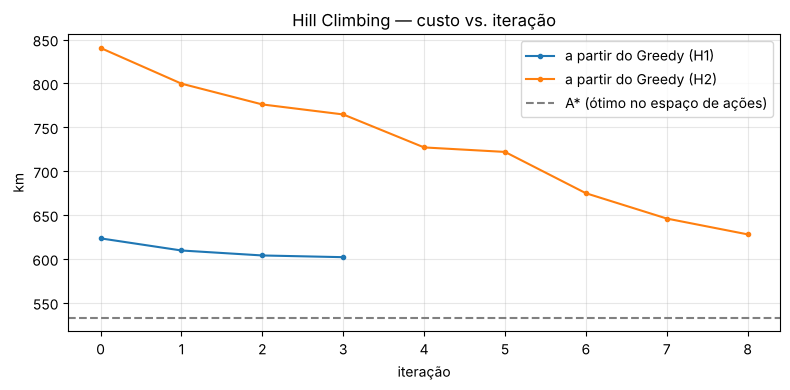

In [10]:
plot_history({f"a partir do Greedy ({'H1' if h == 'farthest' else 'H2'})": r["history"] for h, r in hc_runs.items()})
if runs[("astar", "farthest")]["result"]:
    plt.axhline(runs[("astar", "farthest")]["result"]["distance_km"], color="grey", ls="--", label="A* (ótimo no espaço de ações)")
    plt.legend()
plt.show()

O Hill Climbing melhora muito o Greedy, mas **pára num ótimo local**, acima do A* — nenhum movimento isolado melhora, embora uma combinação melhorasse. O ponto de partida importa (o resultado herda a "forma" do plano inicial). Escapar exigiria *random restarts* ou *simulated annealing* (Russell & Norvig, 2021, cap. 4).

## 9. CSP - Problema de Satisfação de Restrições

### 9.1 Formulação (um CSP por dia, `python-constraint` 1.4.0)

Os itens são agrupados (mesma encomenda e mesmo produtor → recolhidos juntos; mesma encomenda → entregues juntos). Há três tipos de grupo: `same` (recolhe e entrega hoje), `pick` (recolhe hoje, entrega amanhã) e `deliv` (dormiu no armazém, entrega hoje).

| | |
|---|---|
| **Variáveis** (por grupo g) | `V_g` carrinha; `P_g` hora da recolha; `D_g` hora da entrega |
| **Domínios** | `V_g ∈ {carrinhas}`; `P_g`, `D_g` ∈ slots de 15 min dentro da janela |
| **R1** janelas, **R2** regra das 24 h | unárias → cortam o domínio antes de criar a variável (como o `lesson_domain` do Notebook 91) |
| **R3** entrega ≥ recolha + caminho mínimo pelo armazém | binária (`P_g`, `D_g`) |
| **R4** a mesma carrinha não está em dois sítios | 4-ária: `V_g ≠ V_h` **ou** as horas estão separadas por serviço + viagem (+ armazém) |
| **R5** capacidade | n-ária (`CapacityConstraint`, verifica atribuições parciais) — conservadora: soma o dia inteiro |

Uma **atribuição viável** dá a cada grupo uma carrinha e horas; `assignment_to_routes` transforma-a em rotas (ordena os eventos de cada carrinha, junta visitas, insere o armazém) e o plano é **validado pelo mesmo `simulate_plan`** dos outros algoritmos. O CSP é uma aproximação (R4 compara pares, slots de 15 min, R5 conservadora): por isso a validação final é indispensável.

In [11]:
(csp_plan, csp_result, csp_stats), csp_seconds = cached("csp", lambda: solve_csp(problem, time_limit=120))
print("estado:", csp_stats["status"], "| tempo:", round(csp_seconds, 2), "s")
if csp_result:
    print("plano viável (simulate_plan):", csp_result["feasible"], "| km:", round(csp_result["distance_km"], 2))
pd.DataFrame({"variáveis": csp_stats["variables"], "restrições": csp_stats["constraints"],
              "backtracks": csp_stats["backtracks"], "atribuições experimentadas": csp_stats["assignments"]}).rename_axis("dia")

[calculado] csp: 0.2 s
estado: ok | tempo: 0.21 s
plano viável (simulate_plan): True | km: 697.94


,variáveis,restrições,backtracks,atribuições experimentadas
dia,,,,
0,44,304,82,627
1,42,313,1178,4130


In [12]:
day = problem.days[-1]
print(f"Atribuição do dia {day} (uma linha por grupo):")
display_assignment(problem, csp_stats["groups"][day], csp_stats["assignment"][day]) if csp_result else None

Atribuição do dia 1 (uma linha por grupo):


,grupo,carrinha,itens,recolha,entrega,peso (kg)
0,same_o5_p3,1,14 Cebola,d1 07:00,d1 11:15,4.5
1,same_o1_p3,1,"3 Cebola, 4 Castanha",d1 07:45,d1 11:45,12.0
2,same_o6_p3,1,17 Castanha,d1 07:45,d1 11:45,10.0
3,same_o3_p3,1,"8 Cebola, 9 Curgete",d1 07:45,d1 13:45,5.6
4,same_o5_p2,1,15 Curgete,d1 08:30,d1 11:15,4.8
5,same_o1_p2,1,1 Curgete,d1 08:30,d1 11:45,6.3
6,same_o6_p2,1,16 Laranja,d1 08:30,d1 11:45,6.7
7,same_o7_p2,1,18 Ovos,d1 08:30,d1 12:15,5.4
8,same_o3_p2,1,7 Batata,d1 08:30,d1 13:45,6.7
9,same_o1_p1,1,2 Cereja,d1 09:15,d1 11:45,3.7


### 9.2 Comparação de solvers

A biblioteca (1.4.0) tem três solvers. `BacktrackingSolver` (iterativo) e `RecursiveBacktrackingSolver` são **completos** (esgotam a árvore se não houver solução); o `MinConflictsSolver` é **pesquisa local** (atribuição completa aleatória, corrige conflitos durante `steps` passos) — **não garante** encontrar solução e não faz backtracking, por isso "backtracks" não se aplica. Acrescentámos limites de tempo e contadores, que a API não tem.

In [13]:
def csp_row(label, **kw):
    (plan, result, st), seconds = cached("csp_" + label.replace(" ", "_"), lambda: solve_csp(problem, time_limit=60, **kw))
    return {"configuração": label, "estado": st["status"], "km": round(result["distance_km"], 2) if result else None,
            "backtracks": st["backtracks_total"], "atribuições / chamadas": st["assignments"],
            "tempo (s)": round(seconds, 2)}

pd.DataFrame([csp_row("backtracking"), csp_row("recursive", solver="recursive"),
              csp_row("min_conflicts", solver="min_conflicts")])

[calculado] csp_backtracking: 0.2 s
[calculado] csp_recursive: 0.0 s
[calculado] csp_min_conflicts: 19.4 s


,configuração,estado,km,backtracks,atribuições / chamadas,tempo (s)
0,backtracking,ok,697.94,1260.0,"{0: 627, 1: 4130}",0.17
1,recursive,ok,698.49,NaN,"{0: 522, 1: 44}",0.03
2,min_conflicts,no_solution (dia 1),NaN,NaN,"{0: None, 1: None}",19.37


- O **recursivo** percorre os valores pela ordem do domínio (o iterativo tira-os do fim com `pop()`), por isso as duas versões não exploram a árvore pela mesma ordem; "atribuições" no recursivo são chamadas recursivas.
- O **MinConflicts** é aleatório (semente fixa) e falhou no dia 1 do *tiny* em 10 000 passos: as restrições R4 ligam muitas variáveis e corrigir um conflito cria outros.

### 9.3 Tipos de restrições da biblioteca

| Restrição | Relevante? | Uso / motivo |
|---|---|---|
| `FunctionConstraint` (e `lambda`) | sim | R3 e R4 |
| `InSetConstraint` | sim (alternativa) | R1/R2: "a hora está num conjunto de slots" |
| `Constraint` própria | sim | R5 com verificação parcial (`CapacityConstraint`) |
| `MaxSumConstraint` | não | a capacidade é uma soma **condicional** (só os grupos com `V_g = v`); não se exprime com uma soma simples sem variáveis 0/1 extra |
| `AllDifferentConstraint` | não | duas recolhas podem ter a mesma hora (mesma visita ou carrinhas diferentes) |
| `AllEqual`, `ExactSum`, `MinSum`, `NotInSet`, `SomeInSet`, `SomeNotInSet` | não | não correspondem a nenhuma regra do problema |

Comparámos formas **equivalentes** de escrever a mesma restrição:

In [14]:
pd.DataFrame([csp_row("R1 no domínio"), csp_row("R1 com InSetConstraint", windows_as="inset"),
              csp_row("R1 com FunctionConstraint", windows_as="function"),
              csp_row("R5 com FunctionConstraint", capacity_as="function")])

[calculado] csp_R1_no_domínio: 0.3 s
[calculado] csp_R1_com_InSetConstraint: 0.2 s
[calculado] csp_R1_com_FunctionConstraint: 0.2 s
[calculado] csp_R5_com_FunctionConstraint: 0.2 s


,configuração,estado,km,backtracks,atribuições / chamadas,tempo (s)
0,R1 no domínio,ok,697.94,1260,"{0: 627, 1: 4130}",0.33
1,R1 com InSetConstraint,ok,697.94,1260,"{0: 627, 1: 4130}",0.19
2,R1 com FunctionConstraint,ok,697.94,1260,"{0: 627, 1: 4130}",0.19
3,R5 com FunctionConstraint,ok,697.94,1260,"{0: 626, 1: 4130}",0.15


- As três formas da R1 dão **os mesmos backtracks**: a biblioteca aplica as restrições unárias no `preProcess`, ou seja, transforma-as em cortes no domínio. A diferença é só o tempo de construção (domínio do dia inteiro).
- A **R5 com `FunctionConstraint` n-ária** só é testada quando **todas** as carrinhas estão atribuídas (o aviso do Notebook 91): o solver não poda cedo. A classe `CapacityConstraint` soma o que já está atribuído e corta logo.

### 9.4 Heurísticas de escolha de variável e de valor

A biblioteca fixa a ordem **Degree, depois MRV** (`(-nº de restrições, tamanho do domínio)`) e não tem opção para a mudar: copiámos o ciclo do `getSolutionIter` (`CountingBacktrackingSolver`) para comparar:
- **Degree** — a variável que **restringe mais** outras (entra em mais restrições);
- **MRV** — a variável **mais restringida** (menos valores no domínio) — *fail-first* (Haralick & Elliott, 1980);
- **cronológica** — o grupo que abre mais cedo primeiro (natural em escalonamento);
- **LCV** — o valor que deixa **mais** valores aos vizinhos (*least constraining value*);
- **Forward checking** — sempre ligado (o da biblioteca).

In [15]:
pd.DataFrame([csp_row("Degree→MRV (biblioteca)"), csp_row("MRV→Degree", variable_order="mrv_degree"),
              csp_row("MRV", variable_order="mrv"), csp_row("ordem de criação", variable_order="input"),
              csp_row("cronológica", variable_order="chronological"),
              csp_row("Degree→MRV + LCV", value_order="lcv"),
              csp_row("MRV→Degree + LCV", variable_order="mrv_degree", value_order="lcv")])

[calculado] csp_Degree→MRV_(biblioteca): 0.2 s
[calculado] csp_MRV→Degree: 0.0 s
[calculado] csp_MRV: 0.0 s
[calculado] csp_ordem_de_criação: 6.5 s
[calculado] csp_cronológica: 0.0 s
[calculado] csp_Degree→MRV_+_LCV: 0.1 s
[calculado] csp_MRV→Degree_+_LCV: 0.0 s


,configuração,estado,km,backtracks,atribuições / chamadas,tempo (s)
0,Degree→MRV (biblioteca),ok,697.94,1260,"{0: 627, 1: 4130}",0.15
1,MRV→Degree,ok,700.22,113,"{0: 339, 1: 82}",0.02
2,MRV,ok,776.13,229,"{0: 827, 1: 75}",0.03
3,ordem de criação,ok,832.61,48733,"{0: 70, 1: 177147}",6.52
4,cronológica,ok,845.62,5,"{0: 45, 1: 69}",0.01
5,Degree→MRV + LCV,ok,713.05,643,"{0: 63, 1: 1550}",0.10
6,MRV→Degree + LCV,ok,696.52,111,"{0: 340, 1: 72}",0.05


Neste problema, dar prioridade à variável **mais restringida (MRV)** funciona melhor do que à que **mais restringe (Degree)**: as variáveis com mais restrições são as carrinhas (`V_g`, ligadas a todas as R4), que têm 2 valores e pouco informam; as horas com janelas curtas são as que falham primeiro. A ordem pela **ordem de criação** (sem heurística) é a pior. O LCV reduz backtracks mas custa tempo por nó (faz *forward checking* para cada valor).

## 10. Soft constraints

**Preferência escolhida:** reduzir o **tempo de espera** das carrinhas (chegar antes da janela abrir, ou esperar no armazém por outra carrinha). É mensurável (minutos, calculados pela simulação), relevante (tempo pago ao condutor sem trabalho) e entra em conflito com a distância (esperar menos pode obrigar a voltas maiores).

**Custo com soft constraints:** `custo = km + α · espera (min)`. O **α** está em **km por minuto**: quantos km aceitamos percorrer a mais para poupar 1 minuto de espera. Não há normalização: as duas parcelas ficam em km. α = 0 é a Experiência A. As hard constraints continuam todas obrigatórias.

**Coerência com a heurística:** a espera é ≥ 0, por isso as heurísticas (limites inferiores dos km) continuam admissíveis para o novo custo — **nada** é somado a `h(n)`.

**Duas coisas diferentes** (sobretudo no CSP):
1. **Ordenar valores** (ex.: experimentar primeiro a hora mais cedo) é uma **estratégia de pesquisa**: encontra mais depressa soluções "preferidas", mas não compara soluções.
2. **Otimizar** uma função de penalização compara soluções e escolhe a melhor — é o que fazem o A* com `α > 0` e o CSP com `max_solutions = K` (melhor de K atribuições, sem garantia de ótimo).

### Experiência A (hard) vs. Experiência B (hard + soft) com A*

In [16]:
soft = []
for alpha in [0.0, 0.25, 0.5, 1.0, 2.0]:
    (plan, result, stats), seconds = cached(f"astar_soft_{alpha}",
        lambda: solve(problem, "astar", "farthest", alpha=alpha, **LIMITS))
    if result:
        soft.append({"α (km/min)": alpha, "experiência": "A (hard)" if alpha == 0 else "B (hard + soft)",
                     "estado": stats["status"], "km": round(result["distance_km"], 2),
                     "espera (min)": round(result["wait_min"], 1), "duração (min)": round(result["duration_min"], 1),
                     "custo km + α·espera": round(plan_cost(result, "distance_km", alpha), 2),
                     "custo na pesquisa": round(sum(stats["cost"].values()), 2),
                     "nós": stats["expanded_total"], "tempo (s)": round(seconds, 1)})
    else:
        soft.append({"α (km/min)": alpha, "estado": stats["status"]})
soft = pd.DataFrame(soft)
soft

[calculado] astar_soft_0.0: 12.0 s
[calculado] astar_soft_0.25: 13.5 s
[calculado] astar_soft_0.5: 16.8 s
[calculado] astar_soft_1.0: 14.1 s
[calculado] astar_soft_2.0: 4.9 s


,α (km/min),experiência,estado,km,espera (min),duração (min),custo km + α·espera,custo na pesquisa,nós,tempo (s)
0,0.00,A (hard),ok,533.09,224.3,1215.2,533.09,533.09,99257,12.0
1,0.25,B (hard + soft),ok,538.49,164.1,1222.2,579.51,579.51,124431,13.5
2,0.50,B (hard + soft),ok,538.49,164.1,1222.2,620.54,620.54,143368,16.8
3,1.00,B (hard + soft),ok,603.92,78.7,1263.9,682.62,682.62,126410,14.1
4,2.00,B (hard + soft),ok,603.92,78.7,1263.9,761.32,761.32,43478,4.9


**Interpretação.** Com α = 0,25 o A\* aceita ~1% mais km para reduzir a espera em cerca de um quarto; com α ≥ 1 troca ~13% mais km por cerca de dois terços menos espera. O α decide o equilíbrio e deve ser escolhido por quem opera a frota (ex.: custo de 1 min de condutor vs. custo de 1 km).

**Coerência do custo.** O custo que o A\* minimiza é **igual** ao custo final medido pelo `simulate_plan` (colunas "custo km + α·espera" e "custo na pesquisa"). Numa versão anterior diferia 10–20 min de espera: a pesquisa podia fazer duas visitas de recolha seguidas ao mesmo produtor e contava dois serviços de 10 min, enquanto a simulação (como manda o `rules.csv`) as junta numa paragem com um serviço. Essa sequência é igual à opção "recolher tudo" da primeira visita, por isso foi retirada das ações. Há testes de regressão para α = 0; 0,25; 0,5; 1 e 2.

### Soft constraints no CSP: melhor de K atribuições

In [17]:
rows = []
for K in [1, 100, 1000]:
    (plan, result, st), seconds = cached(f"csp_best_of_{K}", lambda: solve_csp(problem, max_solutions=K, alpha=0.5, time_limit=120))
    if result:
        rows.append({"K atribuições por dia": K, "km": round(result["distance_km"], 2),
                     "espera (min)": round(result["wait_min"], 1),
                     "custo km + 0,5·espera": round(plan_cost(result, "distance_km", 0.5), 2), "tempo (s)": round(seconds, 2)})
pd.DataFrame(rows)

[calculado] csp_best_of_1: 0.2 s
[calculado] csp_best_of_100: 0.2 s
[calculado] csp_best_of_1000: 0.7 s


,K atribuições por dia,km,espera (min),"custo km + 0,5·espera",tempo (s)
0,1,697.94,120.9,758.39,0.16
1,100,697.94,120.9,758.39,0.20
2,1000,697.94,45.9,720.89,0.72


O `getSolutionIter` devolve atribuições **vizinhas** na árvore (só mudam as últimas variáveis), por isso K tem de ser grande para a escolha mudar alguma coisa; enumerar **todas** as soluções é impraticável. É otimização limitada a K, não ótima.

## 11. Resultados experimentais — *tiny* e *small*

Os mesmos algoritmos, sem mudar código, em todos os datasets encontrados. Limites: 600 000 nós e 600 s por pesquisa (Greedy), 250 000 nós e 300 s (A* / Weighted A*; no *small* ~10 KB por nó expandido, ou seja, alguns GB de memória), 120 s por dia no CSP.

In [18]:
def experiment(path):
    p = Problem(path)
    rows, greedy_plans = [], {}
    configs = [("Greedy H1", "greedy", "farthest", {}, 600_000, 600), ("Greedy H2", "greedy", "entry", {}, 600_000, 600),
               ("A* H1", "astar", "farthest", {}, 250_000, 300), ("A* H2", "astar", "entry", {}, 250_000, 300),
               ("Weighted A* H2 (w=1,5)", "weighted_astar", "entry", {"weight": 1.5}, 250_000, 300),
               ("Weighted A* H2 (w=3)", "weighted_astar", "entry", {"weight": 3}, 250_000, 300)]
    for label, alg, h, opt, max_it, limit in configs:
        (plan, res, st), sec = cached(f"exp_{alg}_{h}_{opt.get('weight', '')}",
            lambda: solve(p, alg, h, max_iterations=max_it, time_limit=limit, **opt), data_path=path)
        rows.append({"método": label, "estado": st["status"], "km": res and round(res["distance_km"], 2),
                     "espera (min)": res and round(res["wait_min"], 1), "esforço": f"{st['expanded_total']} nós",
                     "tempo (s)": round(sec, 1)})
        if alg == "greedy" and plan:
            greedy_plans[label] = plan
    for label, plan in greedy_plans.items():
        (hp, cost, hist, st), sec = cached(f"exp_hc_{label}", lambda: hill_climbing(p, plan, time_limit=600), data_path=path)
        res = simulate_plan(p, hp)
        rows.append({"método": f"Hill Climbing (de {label})", "estado": st["status"], "km": round(cost, 2),
                     "espera (min)": round(res["wait_min"], 1), "esforço": f"{st['evaluations']} vizinhos",
                     "tempo (s)": round(sec, 1)})
    for label, kw in [("CSP (Degree→MRV)", {}), ("CSP (MRV→Degree)", {"variable_order": "mrv_degree"}),
                      ("CSP (cronológica)", {"variable_order": "chronological"})]:
        (plan, res, st), sec = cached(f"exp_csp_{label}", lambda: solve_csp(p, time_limit=120, **kw), data_path=path)
        rows.append({"método": label, "estado": st["status"], "km": res and round(res["distance_km"], 2),
                     "espera (min)": res and round(res["wait_min"], 1),
                     "esforço": f"{st['backtracks_total']} backtracks", "tempo (s)": round(sec, 1)})
    return pd.DataFrame(rows).assign(dataset=p.name)

results = pd.concat([experiment(path) for path in ALL_DATASETS], ignore_index=True)
results.pivot_table(index="método", columns="dataset", values=["estado", "km", "tempo (s)"], aggfunc="first", sort=False)

[calculado] exp_greedy_farthest_: 116.3 s
[calculado] exp_greedy_entry_: 0.2 s
[calculado] exp_astar_farthest_: 69.1 s
[calculado] exp_astar_entry_: 107.4 s
[calculado] exp_weighted_astar_entry_1.5: 112.0 s
[calculado] exp_weighted_astar_entry_3: 29.8 s
[calculado] exp_hc_Greedy H1: 2.1 s
[calculado] exp_hc_Greedy H2: 3.6 s
[calculado] exp_csp_CSP (Degree→MRV): 120.0 s
[calculado] exp_csp_CSP (MRV→Degree): 120.0 s
[calculado] exp_csp_CSP (cronológica): 120.0 s
[calculado] exp_greedy_farthest_: 1.1 s
[calculado] exp_greedy_entry_: 0.1 s
[calculado] exp_astar_farthest_: 10.8 s
[calculado] exp_astar_entry_: 21.8 s
[calculado] exp_weighted_astar_entry_1.5: 8.7 s
[calculado] exp_weighted_astar_entry_3: 0.1 s
[calculado] exp_hc_Greedy H1: 0.2 s
[calculado] exp_hc_Greedy H2: 0.6 s
[calculado] exp_csp_CSP (Degree→MRV): 0.2 s
[calculado] exp_csp_CSP (MRV→Degree): 0.0 s
[calculado] exp_csp_CSP (cronológica): 0.0 s


estado                 ...  tempo (s)          
dataset                          data_small      data_tiny  ... data_small data_tiny
método                                                      ...                     
Greedy H1                                ok             ok  ...      116.3       1.1
Greedy H2                                ok             ok  ...        0.2       0.1
A* H1                         limit (dia 0)             ok  ...       69.1      10.8
A* H2                         limit (dia 0)             ok  ...      107.4      21.8
Weighted A* H2 (w=1,5)        limit (dia 0)             ok  ...      112.0       8.7
Weighted A* H2 (w=3)                     ok             ok  ...       29.8       0.1
Hill Climbing (de Greedy H1)  local_optimum  local_optimum  ...        2.1       0.2
Hill Climbing (de Greedy H2)  local_optimum  local_optimum  ...        3.6       0.6
CSP (Degree→MRV)              limit (dia 0)             ok  ...      120.0       0.2
CSP (MRV→Degree)              limit (dia 0)             ok  ...      120.0       0.0
CSP (cronológica)             limit (dia 0)             ok  ...      120.0       0.0

[11 rows x 6 columns]

In [19]:
results[["dataset", "método", "estado", "km", "espera (min)", "esforço", "tempo (s)"]]

,dataset,método,estado,km,espera (min),esforço,tempo (s)
0,data_small,Greedy H1,ok,953.17,220.3,558990 nós,116.3
1,data_small,Greedy H2,ok,1081.04,557.9,906 nós,0.2
2,data_small,A* H1,limit (dia 0),NaN,NaN,250001 nós,69.1
3,data_small,A* H2,limit (dia 0),NaN,NaN,250001 nós,107.4
4,data_small,"Weighted A* H2 (w=1,5)",limit (dia 0),NaN,NaN,250001 nós,112.0
5,data_small,Weighted A* H2 (w=3),ok,764.45,492.6,170001 nós,29.8
6,data_small,Hill Climbing (de Greedy H1),local_optimum,768.16,331.3,7765 vizinhos,2.1
7,data_small,Hill Climbing (de Greedy H2),local_optimum,745.44,493.6,11191 vizinhos,3.6
8,data_small,CSP (Degree→MRV),limit (dia 0),NaN,NaN,191016 backtracks,120.0
9,data_small,CSP (MRV→Degree),limit (dia 0),NaN,NaN,98983 backtracks,120.0


## 12. Comparação dos algoritmos

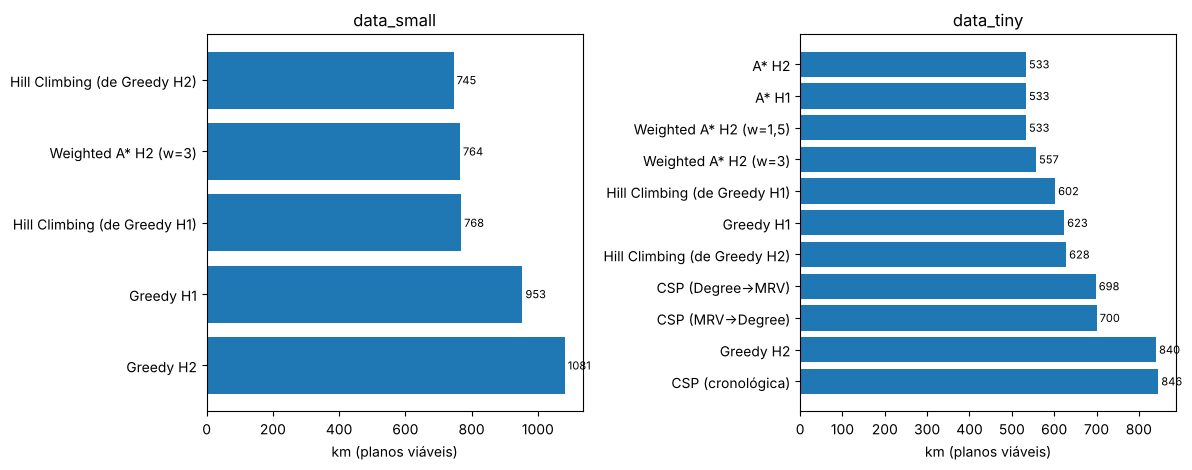

In [20]:
ok = results[results["km"].notna()]
fig, axes = plt.subplots(1, len(ALL_DATASETS), figsize=(6 * len(ALL_DATASETS), 4.8), squeeze=False)
for ax, (name, df) in zip(axes[0], ok.groupby("dataset")):
    df = df.sort_values("km")
    ax.barh(df["método"], df["km"], color="tab:blue")
    for y, v in enumerate(df["km"]):
        ax.text(v, y, f" {v:.0f}", va="center", fontsize=8)
    ax.invert_yaxis(); ax.set_xlabel("km (planos viáveis)"); ax.set_title(name)
plt.tight_layout(); plt.show()

In [21]:
memory = {
    "Greedy H2": measure("Greedy H2", lambda: solve(problem, "greedy", "entry"))[2],
    "Hill Climbing (de Greedy H1)": measure("Hill Climbing", lambda: hill_climbing(problem, runs[("greedy", "farthest")]["plan"]))[2],
    "CSP": measure("CSP", lambda: solve_csp(problem))[2],
}

Greedy H2: Time: 0.21 s, Peak memory: 5062 KB
Hill Climbing: Time: 0.16 s, Peak memory: 511 KB
CSP: Time: 0.20 s, Peak memory: 618 KB


**Análise** (os números são os das tabelas acima):

- **Qualidade.** No *tiny*, o **A\*** dá o melhor plano (o mínimo de cada dia no espaço de pesquisa, secção 5) com as duas heurísticas; Weighted A* (w = 1,5) chega ao mesmo com menos nós. O **Hill Climbing** melhora o Greedy mas fica acima do A*; Greedy e CSP dão planos viáveis mas longos (o CSP não otimiza).
- **Escala.** No *small* (o dobro dos itens, 14 sítios), o **A\*** **não termina** dentro do limite de nós/memória — o espaço de estados cresce exponencialmente. O **Greedy H2** continua quase instantâneo, o **Hill Climbing** melhora-o bastante em segundos, e o **Weighted A\*** só termina com w maior (perde qualidade). É o comportamento esperado de uma pesquisa exata.
- **CSP.** Resolve o *tiny* em frações de segundo, mas **não encontra atribuição no *small*** dentro de 120 s por dia com nenhuma estratégia. Verificámos que o **modelo não é a causa**: o plano viável do Greedy cumpre **todas** as restrições do CSP (com horas exatas) — o problema contínuo tem solução; o backtracking cronológico, com propagação fraca nas R4 (4-árias) e slots de 15 min, não a encontra a tempo.
- **Heurísticas.** No A\* a H1 expandiu muito menos nós no *tiny*; no Greedy, a H2 encontra uma solução com menos nós (no *small*, centenas contra centenas de milhares), mas a H1 dá planos mais curtos.

## 13. Limitações

- **Ótimo do A\*** só no espaço de **macro-ações** e **dia a dia**, dado o stock do dia anterior (o dia 0 não é escolhido a pensar no dia 1). As heurísticas são admissíveis, mas a consistência não foi demonstrada (a pesquisa reabre estados).
- **A\* não escala**: no *small* esgota o limite de nós (~25 KB por nó expandido); o projeto **reporta** `limit` em vez de bloquear ou de devolver um plano parcial.
- **CSP**: slots de 15 min, R4 só entre pares de eventos, R5 conservadora (soma do dia); no *small* não encontra solução no tempo dado.
- **Hill Climbing** pára em ótimos locais.
- Um único centro de recolha; o atributo `refrigerated` é lido mas ignorado (nenhum produto exige frio).

## 14. Melhorias futuras

- Hill Climbing com *random restarts* ou *simulated annealing*; vizinhança que mova dois blocos de uma vez.
- CSP com *restarts* aleatórios, propagação mais forte para a R4 (uma variável de ordem por carrinha) e capacidade momento a momento.
- Planeamento conjunto dos dois dias; heurísticas mais informadas (ex.: árvore de expansão mínima dos sítios por visitar).
- Soft constraints adicionais (equilíbrio de trabalho entre carrinhas) com estudo de sensibilidade dos pesos.

## 15. Conclusão

Construímos um modelo do problema de recolha e entrega com janelas, passagem obrigatória pelo armazém, capacidade, regra das 24 h e trocas entre carrinhas, com um **validador único** (`simulate_plan`) que todos os algoritmos usam. O carregamento lê e valida **qualquer** dataset com o esquema do enunciado. No *tiny*, o A\* encontra o melhor plano do espaço de ações, o Hill Climbing aproxima-se dele a partir do Greedy e o CSP encontra planos viáveis em frações de segundo. No *small*, as diferenças de escala ficam claras: os métodos exatos (A\*, CSP) esbarram nos limites de tempo/memória e os métodos rápidos (Greedy + Hill Climbing, Weighted A\* com w grande) continuam a dar planos viáveis. As soft constraints mostraram que é possível reduzir bastante a espera com pouco aumento de distância (cerca de −27% de espera por +1% de km com α = 0,25), com o custo da pesquisa igual ao custo final simulado.